<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization: Scatter Plots | Portfolio Analysis**
**IBM Skills Network guided lab**


### Project Overview
This notebook examines relationships within a developer survey using scatter plots. Rather than considering each variable separately, the analysis explores how job satisfaction, compensation, age groups, and professional coding experience appear together.

**Guiding question:** What patterns are visible between developers' demographic and professional characteristics, and how confidently can these patterns be interpreted?

**Objectives:** Visualize relationships between two variables; introduce trend lines and bubble plots; compare responses across programming languages, employment categories, and countries; and identify limitations that affect interpretation.

**Approach:** Load survey data → Prepare the variables → Create scatter plots → Add visual dimensions → Compare respondent groups → Review findings and limitations.

**Tools and skills:** Python, Pandas, Matplotlib, NumPy, data preparation, outlier filtering, and exploratory visualization.

*This notebook follows an IBM Skills Network guided lab. The original exercises and attribution are preserved, with additional explanations to make the analysis accessible to technical and non-technical readers.*

Estimated time needed: **45** minutes


### Objectives


In this lab, you will:
- Create and analyze scatter plots to examine relationships between variables.
- Use scatter plots to identify trends and patterns in the dataset.
- Focus on visualizations centered on scatter plots for better data-driven insights.

### Setup: Working with the Database



**Install and import the required libraries**


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━ 5.8/10.8 MB 29.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 33.8 MB/s eta 0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺ 16.5/16.7 MB 100.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 76.6 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

#### Step 1: Load the dataset


In [2]:
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

df = pd.read_csv(file_path)


### Task 1: Exploring Relationships with Scatter Plots



#### 1. Scatter Plot for Age vs. Job Satisfaction



Visualize the relationship between respondents' age (`Age`) and job satisfaction (`JobSatPoints_6`). Use this plot to identify any patterns or trends.<br> The first scatter plot places a numeric representation of age on the horizontal axis and a job-satisfaction score on the vertical axis. It helps show whether satisfaction scores appear concentrated in particular age groups or spread across them.

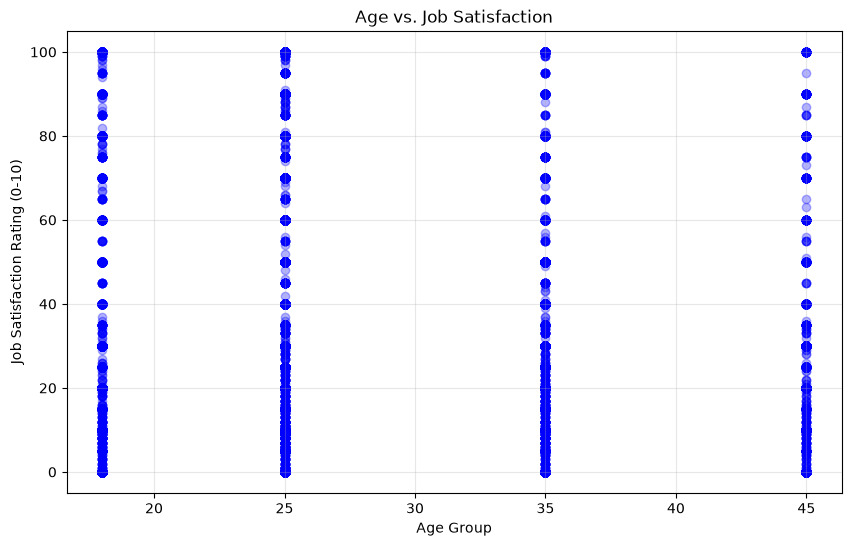

In [3]:
## Write your code here
df_t1q1 = df.dropna(subset=['Age', 'JobSatPoints_6']).copy()
df_t1q1['Age_clean'] = pd.to_numeric(df_t1q1['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t1q1['JobSat_clean'] = df_t1q1['JobSatPoints_6'].astype(int)
df_t1q1 = df_t1q1.dropna(subset=['Age_clean'])

Q1 = df_t1q1['Age_clean'].quantile(0.25)
Q3 = df_t1q1['Age_clean'].quantile(0.75)
IQR = Q3 - Q1
df_t1q1_filtered = df_t1q1[(df_t1q1['Age_clean'] >= Q1 - 1.5 * IQR) & (df_t1q1['Age_clean'] <= Q3 + 1.5 * IQR)]

plt.figure(figsize=(10, 6))
plt.scatter(df_t1q1_filtered['Age_clean'], df_t1q1_filtered['JobSat_clean'], alpha=0.3, color='blue')
plt.title('Age vs. Job Satisfaction')
plt.xlabel('Age Group')
plt.ylabel('Job Satisfaction Rating (0-10)')
plt.grid(True, alpha=0.3)
plt.show()

The points form four vertical bands at approximately 18, 25, 35, and 45. These are representative values taken from age categories, not respondents' exact ages. Job-satisfaction scores span a wide range within every band, although many responses cluster at the lower end of the plotted scale. The chart does not show a clear, consistent increase in satisfaction with age

#### 2. Scatter Plot for Compensation vs. Job Satisfaction


Explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) using a scatter plot.<br> It can help reveal whether higher compensation tends to coincide with higher satisfaction, or whether satisfaction varies across pay levels.

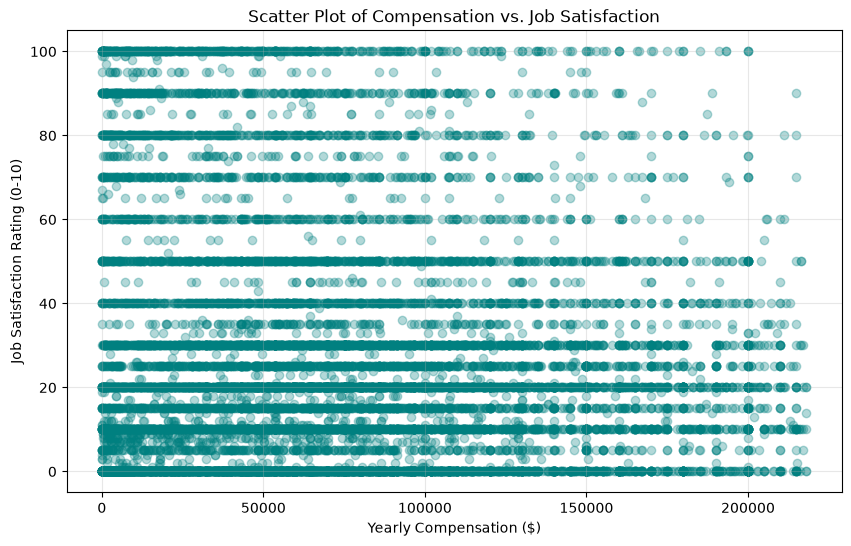

In [4]:
## Write your code here
df_t1q2 = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6']).copy()
df_t1q2['JobSat_clean'] = df_t1q2['JobSatPoints_6'].astype(int)

Q1 = df_t1q2['ConvertedCompYearly'].quantile(0.25)
Q3 = df_t1q2['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t1q2_filtered = df_t1q2[df_t1q2['ConvertedCompYearly'] <= Q3 + 1.5 * IQR]

plt.figure(figsize=(10, 6))
plt.scatter(df_t1q2_filtered['ConvertedCompYearly'], df_t1q2_filtered['JobSat_clean'], alpha=0.3, color='teal')
plt.title('Scatter Plot of Compensation vs. Job Satisfaction')
plt.xlabel('Yearly Compensation ($)')
plt.ylabel('Job Satisfaction Rating (0-10)')
plt.grid(True, alpha=0.3)
plt.show()

Satisfaction scores vary substantially across the compensation range. At both lower and higher reported salaries, points appear at low, middle, and high satisfaction levels. The plot therefore does not show a simple pattern in which higher pay consistently corresponds to higher satisfaction. The horizontal stripes arise because satisfaction is recorded at repeated score values.

### Task 2: Enhancing Scatter Plots


#### 1. Scatter Plot with Trend Line for Age vs. Job Satisfaction



Add a regression line to the scatter plot of Age vs. JobSatPoints_6 to highlight trends in the data.<br> A trend line summarizes the overall direction of the points. Here, the code fits a straight line through the plotted age-group values and satisfaction scores using `numpy.polyfit`.

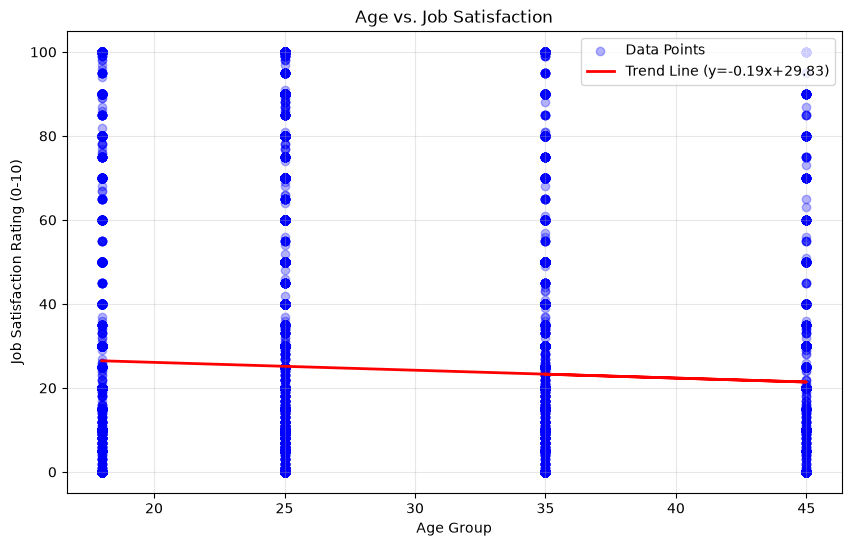

In [5]:
## Write your code here
import numpy as np

df_t2q1 = df.dropna(subset=['Age', 'JobSatPoints_6']).copy()
df_t2q1['Age_clean'] = pd.to_numeric(df_t2q1['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t2q1['JobSat_clean'] = df_t2q1['JobSatPoints_6'].astype(int)
df_t2q1 = df_t2q1.dropna(subset=['Age_clean'])

Q1 = df_t2q1['Age_clean'].quantile(0.25)
Q3 = df_t2q1['Age_clean'].quantile(0.75)
IQR = Q3 - Q1
df_t2q1_filtered = df_t2q1[(df_t2q1['Age_clean'] >= Q1 - 1.5 * IQR) & (df_t2q1['Age_clean'] <= Q3 + 1.5 * IQR)]

x = df_t2q1_filtered['Age_clean']
y = df_t2q1_filtered['JobSat_clean']
m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.3, color='blue', label='Data Points')
plt.plot(x, m*x + b, color='red', linewidth=2, label=f'Trend Line (y={m:.2f}x+{b:.2f})')
plt.title('Age vs. Job Satisfaction')
plt.xlabel('Age Group')
plt.ylabel('Job Satisfaction Rating (0-10)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The red fitted line slopes slightly downward from younger to older age categories. Its displayed equation is approximately y = -0.19x + 29.83. Compared with the broad vertical spread of the points, that decline is small: people within the same age category report very different satisfaction scores. The fitted line suggests a weak negative linear trend in this transformed sample, not evidence that aging reduces job satisfaction.

#### 2. Scatter Plot for Age vs. Work Experience


Visualize the relationship between Age (`Age`) and Work Experience (`YearsCodePro`) using a scatter plot.<br> It is useful for identifying broad differences and the range of experience reported within each category.


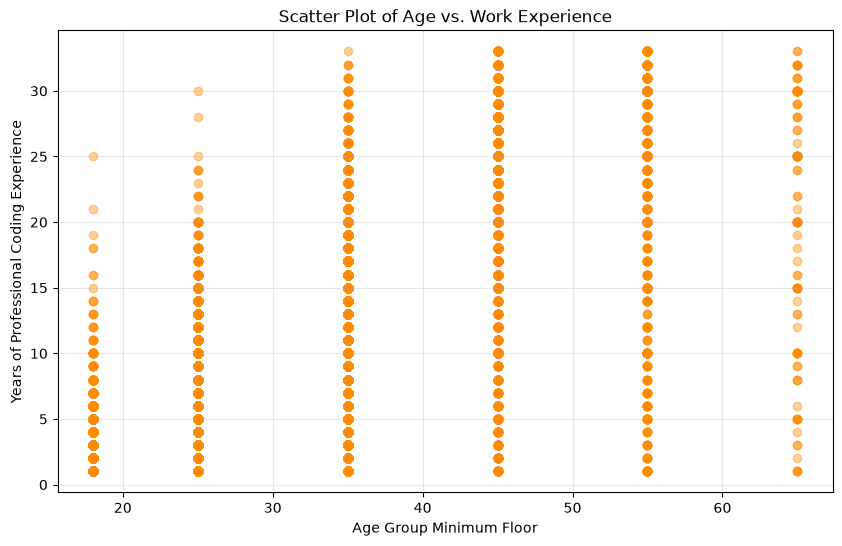

In [6]:
## Write your code here
df_t2q2 = df.dropna(subset=['Age', 'YearsCodePro']).copy()
df_t2q2['Age_clean'] = pd.to_numeric(df_t2q2['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t2q2['YearsPro_clean'] = pd.to_numeric(df_t2q2['YearsCodePro'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t2q2 = df_t2q2.dropna(subset=['Age_clean', 'YearsPro_clean'])

Q1 = df_t2q2['YearsPro_clean'].quantile(0.25)
Q3 = df_t2q2['YearsPro_clean'].quantile(0.75)
IQR = Q3 - Q1
df_t2q2_filtered = df_t2q2[df_t2q2['YearsPro_clean'] <= Q3 + 1.5 * IQR]

plt.figure(figsize=(10, 6))
plt.scatter(df_t2q2_filtered['Age_clean'], df_t2q2_filtered['YearsPro_clean'], alpha=0.4, color='darkorange')
plt.title('Scatter Plot of Age vs. Work Experience')
plt.xlabel('Age Group Minimum Floor')
plt.ylabel('Years of Professional Coding Experience')
plt.grid(True, alpha=0.3)
plt.show()

Younger age groups contain mostly respondents with fewer professional coding years, while older groups include people with considerably more experience. However, the spread is wide: some older respondents report relatively little experience, and experience levels overlap across age groups. Age and professional experience appear related, but they are not interchangeable. People enter software careers at different stages of life.

### Task 3: Combining Scatter Plots with Additional Features


#### 1. Bubble Plot of Compensation vs. Job Satisfaction with Age as Bubble Size



Create a bubble plot to explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), with bubble size representing age.


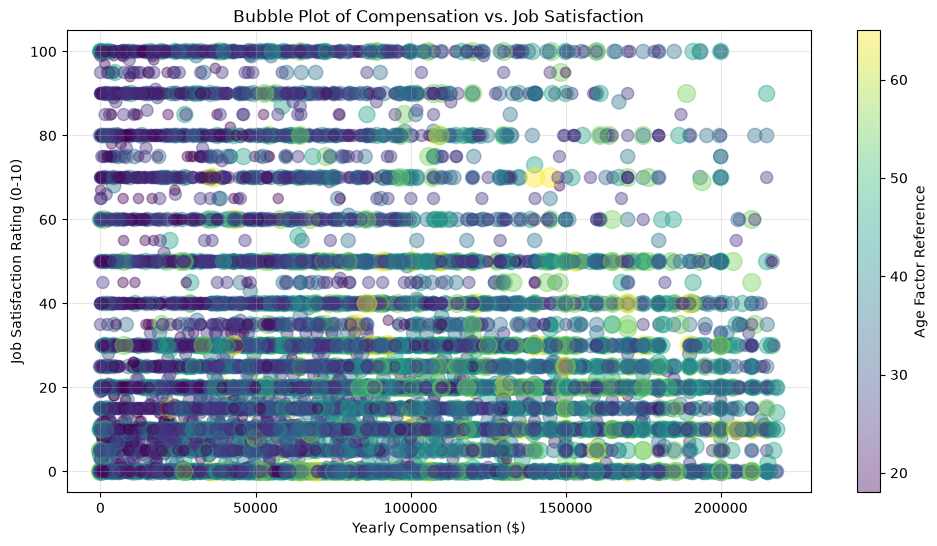

In [7]:
## Write your code here
df_t3q1 = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6', 'Age']).copy()
df_t3q1['Age_size'] = pd.to_numeric(df_t3q1['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t3q1['JobSat_clean'] = df_t3q1['JobSatPoints_6'].astype(int)
df_t3q1 = df_t3q1.dropna(subset=['Age_size'])

Q1 = df_t3q1['ConvertedCompYearly'].quantile(0.25)
Q3 = df_t3q1['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t3q1_filtered = df_t3q1[df_t3q1['ConvertedCompYearly'] <= Q3 + 1.5 * IQR]

plt.figure(figsize=(12, 6))
plt.scatter(
    df_t3q1_filtered['ConvertedCompYearly'], 
    df_t3q1_filtered['JobSat_clean'], 
    s=df_t3q1_filtered['Age_size'] * 3,   
    c=df_t3q1_filtered['Age_size'],     
    alpha=0.4, 
    cmap='viridis'
)
plt.title('Bubble Plot of Compensation vs. Job Satisfaction')
plt.xlabel('Yearly Compensation ($)')
plt.ylabel('Job Satisfaction Rating (0-10)')
plt.colorbar(label='Age Factor Reference')
plt.grid(True, alpha=0.3)
plt.show()

The bubble plot adds age as a third dimension: larger, lighter-colored bubbles represent higher age-reference values. Across the displayed compensation range, satisfaction remains widely dispersed. Different bubble sizes overlap at many salary and satisfaction levels, so there is no obvious age group that consistently occupies only the highest-paying or most satisfied portion of the chart.

#### 2. Scatter Plot for Popular Programming Languages by Job Satisfaction


Visualize the popularity of programming languages (`LanguageHaveWorkedWith`) against job satisfaction using a scatter plot. Use points to represent satisfaction levels for each language.


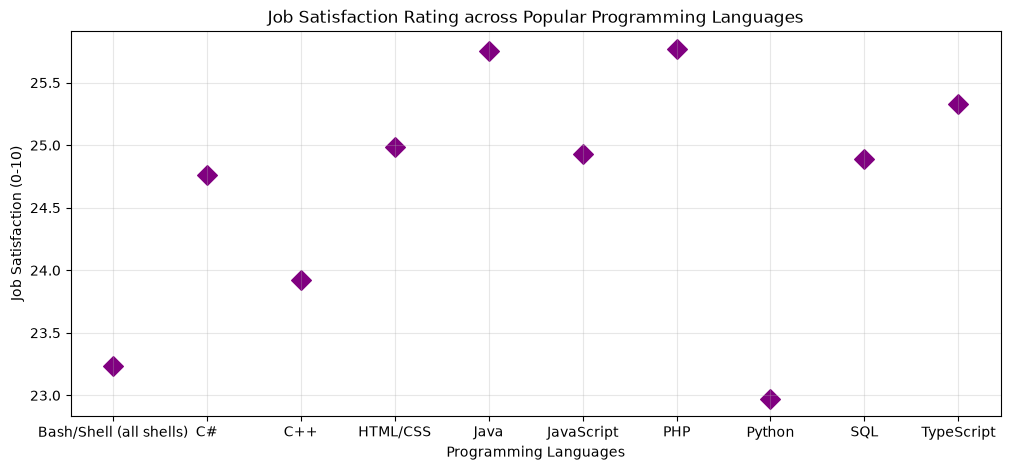

In [8]:
## Write your code here
df_t3q2 = df.dropna(subset=['LanguageHaveWorkedWith', 'JobSatPoints_6']).copy()
df_t3q2['JobSat_clean'] = df_t3q2['JobSatPoints_6'].astype(int)

df_exploded_langs = df_t3q2.assign(Language=df_t3q2['LanguageHaveWorkedWith'].str.split(';')).explode('Language')
top_10_langs = df_exploded_langs['Language'].value_counts().head(10).index
df_top_langs = df_exploded_langs[df_exploded_langs['Language'].isin(top_10_langs)]

lang_satisfaction = df_top_langs.groupby('Language')['JobSat_clean'].mean().reset_index()

plt.figure(figsize=(12, 5))
plt.scatter(lang_satisfaction['Language'], lang_satisfaction['JobSat_clean'], color='purple', s=100, marker='D')
plt.title('Job Satisfaction Rating across Popular Programming Languages')
plt.xlabel('Programming Languages')
plt.ylabel('Job Satisfaction (0-10)')
plt.grid(True, alpha=0.3)
plt.show()

The ten language categories have mean plotted satisfaction values of roughly 23 to 26. Java and PHP are among the highest in this display, while Python and Bash/Shell appear among the lowest. The overall differences are relatively small on the chart's full satisfaction scale.

### Task 4: Scatter Plot Comparisons Across Groups


#### 1. Scatter Plot for Compensation vs. Job Satisfaction by Employment Type


Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), categorized by employment type (`Employment`). Use color coding or markers to differentiate between employment types.


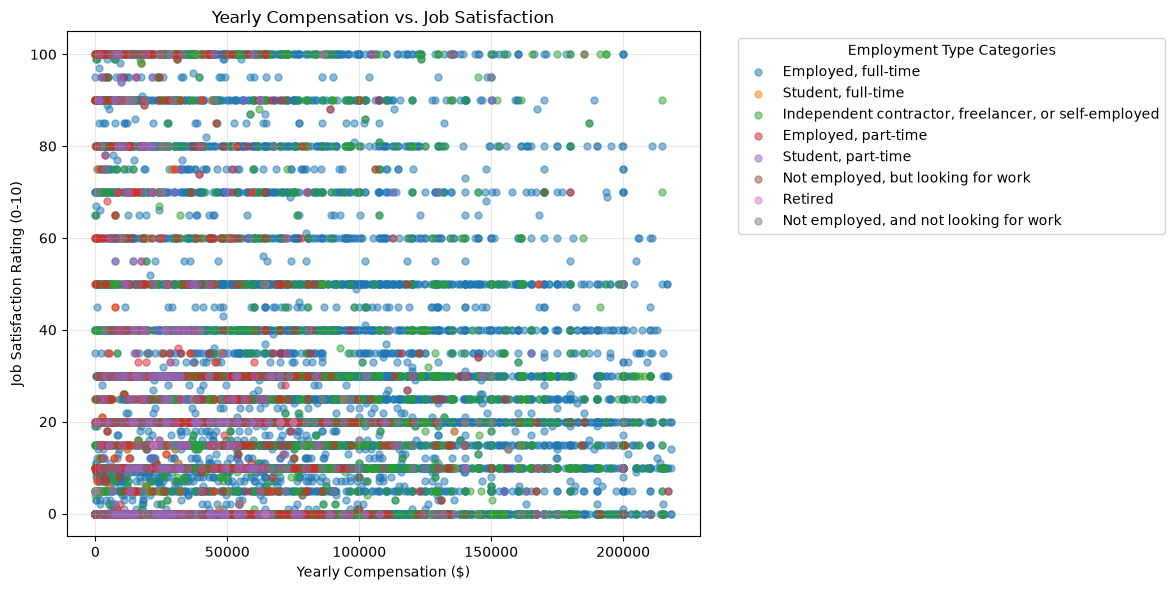

In [9]:
## Write your code here
df_t4q1 = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6', 'Employment']).copy()
df_t4q1['JobSat_clean'] = df_t4q1['JobSatPoints_6'].astype(int)


df_exploded_emp = df_t4q1.assign(Employment=df_t4q1['Employment'].str.split(';')).explode('Employment')

Q1 = df_exploded_emp['ConvertedCompYearly'].quantile(0.25)
Q3 = df_exploded_emp['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t4q1_filtered = df_exploded_emp[df_exploded_emp['ConvertedCompYearly'] <= Q3 + 1.5 * IQR]

plt.figure(figsize=(12, 6))
for emp_type in df_t4q1_filtered['Employment'].unique():
    subset = df_t4q1_filtered[df_t4q1_filtered['Employment'] == emp_type]
    plt.scatter(subset['ConvertedCompYearly'], subset['JobSat_clean'], alpha=0.5, label=str(emp_type), s=25)

plt.title('Yearly Compensation vs. Job Satisfaction')
plt.xlabel('Yearly Compensation ($)')
plt.ylabel('Job Satisfaction Rating (0-10)')
plt.legend(title='Employment Type Categories', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The full-time category contributes many of the visible points and spans a broad range of compensation and satisfaction. Other employment categories overlap considerably with it. Within most groups, high and low satisfaction values occur at different pay levels; the plot does not reveal a clean separation between employment categories.

#### 2. Scatter Plot for Work Experience vs. Age Group by Country


Compare work experience (`YearsCodePro`) across different age groups (`Age`) and countries (`Country`). Use colors to represent different countries and markers for age groups.


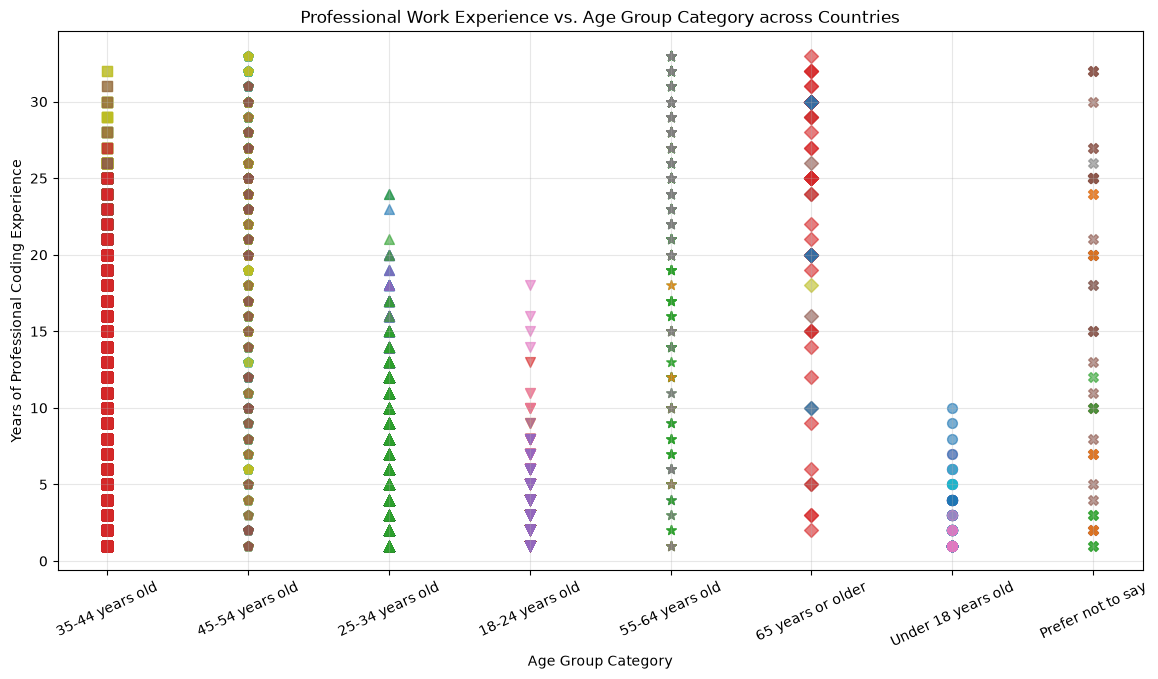

In [11]:
## Write your code here
df_t4q2 = df.dropna(subset=['YearsCodePro', 'Age', 'Country']).copy()
df_t4q2['YearsPro_clean'] = pd.to_numeric(df_t4q2['YearsCodePro'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t4q2 = df_t4q2.dropna(subset=['YearsPro_clean'])

top_5_nations = df_t4q2['Country'].value_counts().head(5).index
df_filtered_nations = df_t4q2[df_t4q2['Country'].isin(top_5_nations)]

Q1 = df_filtered_nations['YearsPro_clean'].quantile(0.25)
Q3 = df_filtered_nations['YearsPro_clean'].quantile(0.75)
IQR = Q3 - Q1
df_t4q2_filtered = df_filtered_nations[df_filtered_nations['YearsPro_clean'] <= Q3 + 1.5 * IQR]

age_markers = {'Under 18 years old': 'o', '18-24 years old': 'v', '25-34 years old': '^', 
               '35-44 years old': 's', '45-54 years old': 'p', '55-64 years old': '*', 
               '65 years or older': 'D', 'Prefer not to say': 'X'}

plt.figure(figsize=(14, 7))
for nation in df_t4q2_filtered['Country'].unique():
    nation_subset = df_t4q2_filtered[df_t4q2_filtered['Country'] == nation]
    
    for age_group in nation_subset['Age'].unique():
        if age_group in age_markers:
            final_subset = nation_subset[nation_subset['Age'] == age_group]
            plt.scatter(
                final_subset['Age'], 
                final_subset['YearsPro_clean'], 
                alpha=0.6, 
                label=f"{nation} ({age_group})" if not final_subset.empty else "",
                marker=age_markers[age_group],
                s=50
            )

plt.title('Professional Work Experience vs. Age Group Category across Countries')
plt.xlabel('Age Group Category')
plt.ylabel('Years of Professional Coding Experience')
plt.xticks(rotation=25)
plt.grid(True, alpha=0.3)
plt.show()

Experience generally reaches higher values in older age categories, while younger groups show a narrower range. The plot also contains substantial overlap: respondents in the same age band report different experience levels. Country colors are mixed within several bands, making it difficult to identify a reliable country-level difference from the displayed points alone

### Key Findings and Analytical Takeaways
- Scatter plots provide a useful way to examine possible relationships between satisfaction, compensation, age categories, and experience, but the charts alone do not establish causation.
- Age is recorded as a category and converted to a numeric lower boundary for some plots. This supports approximate visual comparisons, not exact age-based analysis.
- IQR-based filtering reduces the influence of high values in several plots, but also changes which responses are represented.
- The programming-language chart compares average satisfaction among language users. It does not measure satisfaction caused by a language or show the popularity counts directly.
- Employment and language questions allow multiple selections, so the same respondent can contribute to more than one group.
- The final country comparison provides a view of the most frequently represented countries in the selected data, not a population-wide international ranking.

### Limitations and Next Steps
These results are exploratory. Missing responses, category-to-number conversions, multiple-choice answers, and outlier filtering all influence the charts. The original notebook primarily produces figures rather than printed summary statistics, so I have not assigned numerical trends or strengths of association that are not shown in the saved outputs.

For a deeper analysis, I would retain age as an ordered category, examine the effect of filtering on sample sizes, verify compensation units, and calculate appropriate group summaries and association measures. I would also simplify crowded plots to improve readability for stakeholders.

### Skills Demonstrated
- Data preparation: Handling missing values, converting text fields, and applying IQR-based filters.
- Visualization: Creating scatter plots, trend lines, bubble plots, and grouped comparisons.
- Exploratory analysis: Comparing satisfaction, compensation, experience, and respondent categories.
- Communication: Distinguishing visible patterns from conclusions the data cannot support.

### Summary


After completing this lab, you will be able to:
- Analyze how numerical variables relate across specific groups, such as employment types and countries.
- Use scatter plots effectively to represent multiple variables with color, size, and markers.
- Gain insights into compensation, satisfaction, and demographic trends using advanced scatter plot techniques.

*Attribution: Original lab content and authorship belong to IBM Skills Network.*

### Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
